# Vibrations TBA

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/ch2D-vibrations.ipynb)
:::


In [17]:
#| tags: [remove-cell, remove-stdout]

####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import rdkit
except ImportError:
    !pip -q install rdkit
    import rdkit

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    plt.style.use("styles/tufte.mplstyle")
    nproc = 4          # my own computer limit: 4 threads. Yours may vary. Adjust this number to your system's capabilities. Don't include efficiency cores as they are not well-suited for Psi4 calculations.

import psi4_helpers as ph

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output/ch2/2D-vibrations")
output_dir.mkdir(parents=True, exist_ok=True)


# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
psi4.set_memory("2 GB")

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = True

**Rock and roll**! At a minimum on the potential energy surface, the **curvature** (second derivative) of the energy tells us how **stiff** each motion is. From the curvature and the atomic masses, *Psi4* calculates the **vibrational frequencies** and **normal modes**, which we can **compare** with the infrared spectrum.


```{note} The Invisible Code
:class: dropdown
There is a **block** of code **at the top** if each notebook that is **invisible** in this web book. When **running** the notebook in *Colab* or on your own computer, that cell will be visible and needs to be the **first** block **executed**. This setup block at the top of each notebook **sets the resources** that *Psi4* may use. It will sense the environment and, if you are using *Colab*, the code will **install** required *Python* tools. On your own computer you will have set up your *Python* environment in advance according to the [setup instructions](ch1-setup.md).

In this notebook, the hidden code also decalres the **destination** for all output file (`output/ch2/2D-vibrations`), sets the **number of processors** to use (2 for *Colab*, 4 for my own computer), and sets **flags** that affect many different cells in the notebook. Here, the flag `INTERACTIVE = False` will make all moelcular images render as **still images**. If you set `INTERACTIVE = True`, then those images will be 3-dimensional **interactive objects** that you can spin around and observe at any angle. The interactive images can be very, **very large** when they include molecular orbitals and other objects. The web book is executed with `INTERACTIVE = False` so that I **don't break** the cloud provider that is serving these pages. You can set it to `True` when running your calculation in *Colab* or on your own machine.
```
The energy of a molecule depends on where its nuclei are. A **geometry optimization** moves the atoms downhill on this **potential energy surface** until it reaches a minimum: the structure where all the forces on the atoms are zero.

We are moving on from the basics and **starting to explore** some useful capabilities. 

## What You Will Learn

- How to run `psi4.frequency()` and read the **frequencies**, symmetries and IR **intensities**.
- How to **draw** the normal modes, as arrows or as an **animation**.
- Why **frequencies** must be calculated at an optimized structure, **with the same method and basis set**.
- Why calculated (harmonic) frequencies are **higher** than the **observed** bands, and how **scale factors** are used.

## Benchmarks

[](#tbl-levels-2D) shows the experimental values for the vibrations in a water molecule (in gas phase). We will use these as our standards.


```{table} Experimental values for water (cm⁻¹)
:label: tbl-levels-2D
:align: center

| Mode | Symmetry | Fundamental | Harmonic  |
|---|---|---|---|
| bend, $\nu_2$ | $a_1$ | 1595 | 1649 |
| symmetric stretch, $\nu_1$ | $a_1$ | 3657 | 3832 |
| antisymmetric stretch, $\nu_3$ | $b_2$ | 3756 | 3943 |
```

The **fundamental** is the band we observe in the IR spectrum, the jump from the lowest vibrational level to the next. The **harmonic** value is what the frequency would be if the bond behaved like a perfect spring. Real bonds get softer as they stretch (they are **anharmonic**), so the observed fundamentals are about 3–5% lower. *Psi4* calculates harmonic frequencies, so the harmonic column is the fair comparison for our results.

We can now enter that data into varibale for use later in the code of this notebook.

In [18]:
#| label: variables-2D

r_exp = 0.9578      # Å
a_exp = 104.48      # degrees

exp_fundamental = np.array([1595, 3657, 3756])
exp_harmonic    = np.array([1649, 3832, 3943])

## Optimize and Calculate Frequencies

The [following code block](#freq-calc-2D) performs a geometryc optimization followed by a frequency calculation (Hessian matrix).

```{note} Psi4 settings in this cell
:class: dropdown
`psi4.frequency("hf", molecule=water, return_wfn=True)`
: Calculates the **Hessian** (the matrix of second derivatives of the energy) and analyses it. For HF, *Psi4* computes the Hessian analytically. For methods without analytic second derivatives (most DFT functionals, MP2, CCSD(T)) it uses **finite differences** of gradients: it displaces the atoms a little in each direction and measures how the forces change. That takes several gradient calculations, so frequencies cost more than an optimization.

`dertype` (not set)
: Forces a choice: `dertype=0` uses finite differences of energies (slowest, but works for any method), `dertype=1` finite differences of gradients. *Psi4* chooses the best available automatically.

Same level for optimization and frequencies
: The harmonic analysis is only valid where the gradient is zero **for that method and basis set**. A structure optimized at a different level is not a stationary point at this level.
```

In [19]:
#| label: freq-calc-2D

psi4.set_output_file("output/04-vibrations.out", False);
psi4.set_options({"scf_type": "pk"})

water = psi4.geometry(f"""
0 1
O
H 1 {r_exp}
H 1 {r_exp} 2 {a_exp}
""")

psi4.optimize("hf/6-31g*", molecule=water)
E, wfn = psi4.frequency("hf/6-31g*", molecule=water, return_wfn=True)

freqs = wfn.frequencies().np
print("HF/6-31G* frequencies (cm-1):", ", ".join(f"{f:.1f}" for f in freqs))

Optimizer: Optimization complete!
HF/6-31G* frequencies (cm-1): 1826.1, 4069.8, 4188.4


### The Frequencies

The `frequency_analysis` dictionary holds much more: the symmetry of each mode, its IR intensity, its force constant and the displacement vectors. It includes all $3N = 9$ motions; the label `TRV` tells us which are **t**ranslations, **r**otations and **v**ibrations. [](#vib-analysis-2D) 

In [20]:
#| label: vib-analysis-2D
#| tags: [hide-input]
#| caption: Frequency analysis for water at HF/6-31G*
vib = wfn.frequency_analysis
is_vib = np.array([t in "V" for t in vib["TRV"].data])

table = pd.DataFrame({
    "frequency (cm-1)": vib["omega"].data[is_vib].real,
    "symmetry": np.array(vib["gamma"].data)[is_vib],
    "IR intensity (km/mol)": vib["IR_intensity"].data[is_vib],
    "force constant (mdyn/Å)": vib["k"].data[is_vib],
})
table_rounded = table.round(2)
display(table_rounded)


,frequency (cm-1),symmetry,IR intensity (km/mol),force constant (mdyn/Å)
0,1826.10,A1,107.35,2.13
1,4069.84,A1,18.21,10.20
2,4188.41,B2,58.29,11.19


## Visualizing the Normal Modes

Each normal mode is a set of **displacement vectors**, one for each atom that describes a vibration. The interactive animations produced using the code below show the vibrations. Set `INTERACTIVE = False` in the first cell and rerun the notebook to get each vibration as a still image. In the still images, arrows show which way each atom moves at the start of the vibration (half a cycle later they all point the other way). 

In [26]:
def mode_vectors(vib, mode):
    """Displacement of each atom, shape (natom, 3), in one vibrational mode (0 = lowest frequency)."""
    is_vib = np.array([t == "V" for t in vib["TRV"].data])
    return vib["x"].data[:, is_vib][:, mode].reshape(-1, 3)

for mode in range(3):
    label = f"Mode {mode + 1}: {table['frequency (cm-1)'][mode]:.0f} cm-1 ({table['symmetry'][mode]})"
    print(label)
    ph.show_mode(water, mode_vectors(vib, mode), interactive=INTERACTIVE, amplitude=0.3, title=label)

Mode 1: 1826 cm-1 (A1)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Mode 2: 4070 cm-1 (A1)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Mode 3: 4188 cm-1 (B2)


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

The lowest mode is the **bend** (scissoring). The two higher modes are the **symmetric** stretch (both O–H bonds stretch together, $a_1$) and the **antisymmetric** stretch (one stretches while the other shrinks, $b_2$).

```{note} What do $a_1$, $b_1$ and $b_2$ mean?
:class: dropdown
The labels in the symmetry column describe how each vibration behaves under the **symmetry operations** of the molecule. Water belongs to the **point group** $C_{2v}$. It has a **two-fold rotation axis** ($C_2$) through the oxygen, bisecting the H–O–H angle, and two **mirror planes** that contain that axis: one in the plane of the molecule and one perpendicular to it.

Imagine freezing the vibration at one instant, then applying each operation. If the displaced molecule looks the same, the vibration is **symmetric** with respect to that operation. If every arrow points the opposite way, it is **antisymmetric**.

- **$a$ or $b$**: $a$ is symmetric with respect to the $C_2$ rotation; $b$ is antisymmetric.
- **subscript 1 or 2**: tells us how the vibration behaves under the mirror planes. $a_1$ is symmetric under everything, the **totally symmetric** motion. $b_1$ and $b_2$ are each symmetric under one mirror plane and antisymmetric under the other.

For water, the **bend** and the **symmetric stretch** keep all the symmetry of the molecule ($a_1$). The **antisymmetric stretch** lengthens one O–H bond while shortening the other, so rotating by 180° reverses the motion ($b_2$).

**Lowercase** labels ($a_1$) are normally used for a single vibration and **uppercase** ($A_1$) for the overall **symmetry** of a state. *Psi4* prints uppercase. Whether the antisymmetric stretch is called $b_1$ or $b_2$ depends only on which plane the molecule is placed in, so different books and programs may disagree.

These labels are **useful** because they predict which bands appear: in $C_{2v}$, vibrations of $a_1$, $b_1$ and $b_2$ symmetry are **IR active**, while $a_2$ vibrations are not. Water has no $a_2$ vibrations, so all three of its bands show up in the IR spectrum.
```

## A Calculated IR Spectrum

The IR **intensity** measures how much the **dipole moment** changes during the vibration. We draw it as a **stick spectrum** in [](#spectrumIR-2d).

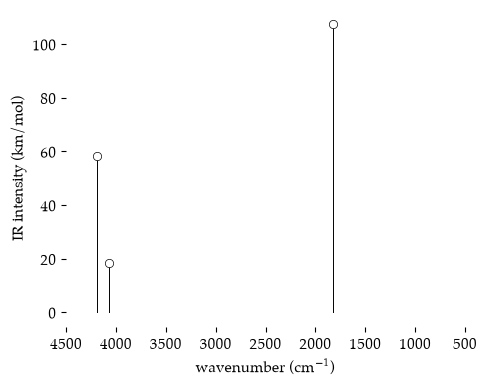

In [ ]:
#| label: spectrumIR-2d
#| tags: [hide-input]
#| caption: HF/6-31G* stick spectrum of water

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
for f, I in zip(table["frequency (cm-1)"], table["IR intensity (km/mol)"]):
    ax.plot([f, f], [0, I], color="black", linewidth=0.7)
ax.plot(table["frequency (cm-1)"], table["IR intensity (km/mol)"], linestyle="none", marker="o",
        markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
ax.set_xlim(4500, 500)              # IR spectra are drawn with wavenumber decreasing
ax.set_xlabel(r"wavenumber (cm$^{-1}$)")
ax.set_ylabel("IR intensity (km/mol)")
#ax.set_title("HF/6-31G* stick spectrum of water")
plt.show()

## Comparing Levels of Effort

Calculated frequencies are **harmonic**: they assume each bond behaves like a perfect spring. Real bonds get weaker as they stretch (they are *anharmonic*), so observed fundamentals are lower. HF also makes bonds too stiff because it lacks electron correlation. Both errors make HF frequencies too high.

A common fix is to multiply calculated frequencies by an empirical **scale factor** fitted to many molecules, for example about 0.895 for HF/6-31G* and about 0.961 for B3LYP/6-31G* {cite:p}`10.1021/jp960976r`, {cite:p}`10.1021/jp073974n`, {cite:p}`10.1021/ct100326h`. Scaled frequencies are compared with observed fundamentals.

```{note} Psi4 settings for the higher levels
:class: dropdown
`freeze_core: True` leaves the O 1s electrons uncorrelated in MP2 and CCSD(T) (see the *Level of Effort* notebook). `scf_type: "df"` speeds up the SCF part. For CCSD(T) the Hessian comes from finite differences of analytic gradients, which is why it is the slowest step in this notebook (about a minute on *Colab*).

*Alternatives:* `b3lyp/def2-tzvp` or `wb97x-d/def2-tzvp` (better DFT frequencies), `mp2/aug-cc-pvtz`. *Psi4* can also calculate anharmonic corrections only through external programs, so we rely on comparison with harmonic experimental values or on scaling.
```

In [ ]:
#| label: freq-levelofeffort
#| tags: [hide-input, remove-stdout]
#| caption: Table of frequency calculations with different levels of effort.

import time

psi4.set_options({"scf_type": "df", "freeze_core": True})
levels = ["hf/6-31g*", "b3lyp/6-31g*", "mp2/cc-pvtz", "ccsd(t)/cc-pvtz"]

rows = []
for level in levels:
    mol = psi4.geometry(f"""
    0 1
    O
    H 1 {r_exp}
    H 1 {r_exp} 2 {a_exp}
    """)
    t0 = time.perf_counter()
    psi4.optimize(level, molecule=mol)
    E, w = psi4.frequency(level, molecule=mol, return_wfn=True)
    f = np.sort(w.frequencies().np)
    rows.append({"level": level, "bend": f[0], "sym. stretch": f[1], "antisym. stretch": f[2],
                 "time (s)": time.perf_counter() - t0})

rows.append({"level": "harmonic", "bend": 1649, "sym. stretch": 3832, "antisym. stretch": 3943})
rows.append({"level": "fundamental", "bend": 1595, "sym. stretch": 3657, "antisym. stretch": 3756})
freq_table = pd.DataFrame(rows)
freq_table.round(0)

Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!
Optimizer: Optimization complete!


,level,bend,sym. stretch,antisym. stretch,time (s)
0,hf/6-31g*,1826.0,4070.0,4188.0,3.0
1,b3lyp/6-31g*,1713.0,3728.0,3849.0,6.0
2,mp2/cc-pvtz,1652.0,3855.0,3976.0,7.0
3,ccsd(t)/cc-pvtz,1669.0,3841.0,3945.0,35.0
4,harmonic,1649.0,3832.0,3943.0,NaN
5,fundamental,1595.0,3657.0,3756.0,NaN


Notice how HF **overestimates** every frequency by about 10 %. MP2 and CCSD(T) with the cc-pVTZ basis set come within a few tens of cm⁻¹ of the **harmonic** experimental values, yet they are still well above the **observed** bands. That remaining gap is anharmonicity, not an error in the method.

The **scaling factors** convert the calculated harmonic frequency for a given method to the value of the observed fundamental frequency. If we use the accepted s**caling factor** for HF/6-31G* frequency calculations we would see that the calculated harmonic frequency for the symmetric stretch is $4070 \times 0.895 = 3642$ which is very close to the fundamental frequency of $3657$. 

B3LYP/6-31G* lands *below* the harmonic values and closer to the observed bands. That is a lucky cancellation of errors, which is why its **scale factor** is close to 1. I read the review by {cite:t}`10.1021/jp073974n` and observe that the method determines the **scaling factor** more than the basis set. Across a range of basis sets the **scaling factors** are close to 0.91 for HF, 0.97 for B3LYP and 0.95 for MP2 methods.

## A Common Mistake: Frequencies at the Wrong Structure

What happens if we calculate HF/6-31G* frequencies at a structure that was never optimized (or that was optimized at a different level)? The structure is no longer at the bottom of the HF/6-31G* energy surface, so the analysis is no longer valid. Always optimize at the same level of theory as you use for the frequency calculations.

```{important} Imaginary frequencies
A true minimum has only real (positive) frequencies. An **imaginary** frequency (printed as a negative number or with an `i`) means the structure is at a **saddle point**: moving along that mode lowers the energy. That is what we want for a transition state, but for a stable molecule it means the optimization stopped in the wrong place. In the *Bending Scan* notebook we meet one: linear water.
```

## Summary
- `psi4.frequency()` gives **frequencies**, symmetries, IR intensities and normal modes.
- Calculate frequencies at a structure optimized with the **same method and basis set**.
- Calculated **frequencies** are harmonic; compare them with harmonic experimental values or **scale them** before comparing with observed bands.
- HF frequencies are about 10 % **too high**; correlated methods do much better. All **results** need to be **scaled** to match **observed** frequencies.